# 实验 6　主要人物出场规律分析

## 任务要求

1. 以章节为单位，统计 4—6 位核心人物在每章中的出现次数。
2. 绘制多人物出场曲线图，图中能区分不同人物。
3. 选择至少 2 位人物，描述出场高峰所在章节并结合情节解释。
4. 尝试把全书粗分为几个叙事阶段，说明不同阶段由哪些人物主导。

## 方法说明

- 复用实验 5 的别名归一规则，避免同一人物的不同称谓被拆开统计。
- 除绝对次数外，还计算**出场密度**（每千字出场次数），以消除章节长度差异带来的偏差。

In [1]:
# 让 notebook 在 notebooks/ 或仓库根目录下都能找到 src/ 包
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "sanguo_nlp").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from sanguo_nlp.paths import FIGURES_DIR, TABLES_DIR, ensure_output_dirs

ensure_output_dirs()
print("已定位仓库根目录:", ROOT.name)

已定位仓库根目录: sanguo-nlp-lab


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from sanguo_nlp.corpus import load_chapters
from sanguo_nlp.lexicons import load_aliases
from sanguo_nlp.mentions import count_mentions_by_chapter
from sanguo_nlp.plotting import use_chinese_font

use_chinese_font()

chapters = load_chapters()
aliases = load_aliases()
core = ["刘备", "曹操", "诸葛亮", "孙权", "关羽"]

trends = count_mentions_by_chapter(chapters, aliases)
trends.to_csv(TABLES_DIR / "character_trends.csv", index=False, encoding="utf-8-sig")
print("共统计", len(trends), "章、", trends.shape[1] - 1, "位人物")
trends[["章号"] + core].head()

共统计 120 章、 16 位人物


,章号,刘备,曹操,诸葛亮,孙权,关羽
0,1,50,2,0,0,11
1,2,47,5,0,0,4
2,3,0,7,0,0,0
3,4,0,23,0,0,0
4,5,23,14,0,0,11


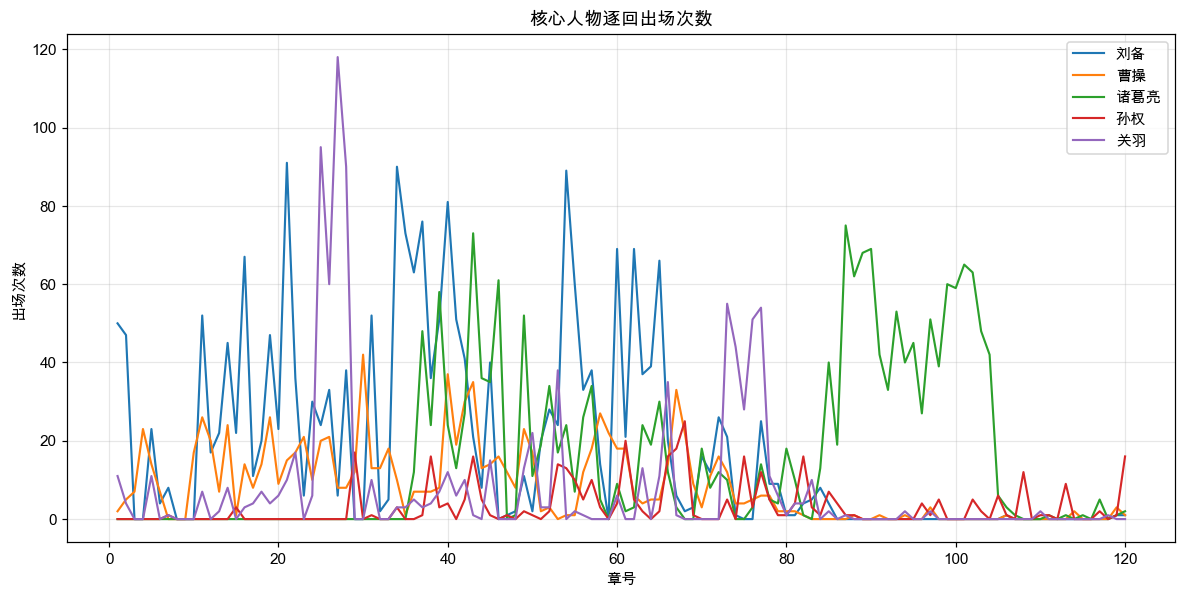

In [3]:
fig, ax = plt.subplots(figsize=(13, 6))
for name in core:
    ax.plot(trends["章号"], trends[name], label=name, linewidth=1.4)
ax.set_xlabel("章号")
ax.set_ylabel("出场次数")
ax.set_title("核心人物逐回出场次数")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(FIGURES_DIR / "character_trends.png")
plt.show()

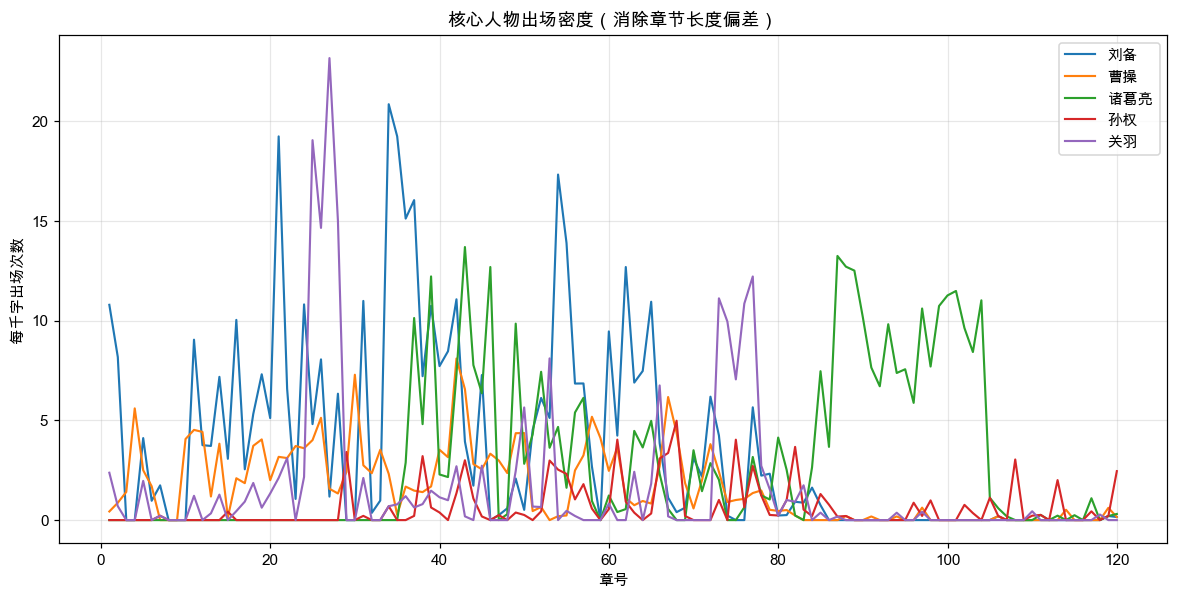

In [4]:
chapter_length = chapters["正文"].str.len()
density = trends.copy()
density[core] = density[core].div(chapter_length, axis=0) * 1000

fig, ax = plt.subplots(figsize=(13, 6))
for name in core:
    ax.plot(density["章号"], density[name], label=name, linewidth=1.4)
ax.set_xlabel("章号")
ax.set_ylabel("每千字出场次数")
ax.set_title("核心人物出场密度（消除章节长度偏差）")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(FIGURES_DIR / "character_trends_density.png")
plt.show()

In [5]:
for name in core:
    peaks = trends.nlargest(5, name)[["章号", name]]
    spots = "、".join(f"第{int(row['章号'])}回" for _, row in peaks.iterrows())
    print(f"{name} 出场最多的 5 回：{spots}")

刘备 出场最多的 5 回：第21回、第34回、第54回、第40回、第37回
曹操 出场最多的 5 回：第30回、第40回、第43回、第67回、第42回
诸葛亮 出场最多的 5 回：第87回、第43回、第90回、第89回、第101回
孙权 出场最多的 5 回：第68回、第61回、第67回、第29回、第38回
关羽 出场最多的 5 回：第27回、第25回、第28回、第26回、第73回


## 讨论与实验记录

- **出场次数高不等于更重要**：人物的重要性更多体现在推动情节、被作者着墨的程度，而不是名字出现的次数。
- **章节长度会带来偏差**：长章节天然更容易出现人名，因此同时给出“每千字出场次数”更公平。
- 结合曲线可以发现：刘备在前 40 回出场密集（峰值第 21、34、37、40、54 回），对应桃园结义到荆州时期的群雄混战；诸葛亮在 35 回之后显著上升（峰值第 43、87、89、90、101 回），对应三顾茅庐之后的主线转移；关羽在第 25—28 回出现明显尖峰，对应下邳之围到千里走单骑。
- 可将全书大致分为三个阶段：前 40 回群雄逐鹿（刘备、曹操、关羽为主）；40—80 回三国鼎立形成（诸葛亮、孙权、周瑜为主）；80 回之后北伐与三国归晋（诸葛亮、司马懿、姜维为主）。

**实验记录**

- 本实验未出现报错；AI 助手协助编写按章统计与循环绘图代码，全部结果均在本地手动运行验证。